# 10 · Unit concentration: the Bedekar et al. (2024) example, tracked and checked against MF6 GWT

Bedekar et al. (2024) describe the **unit-concentration method**. Water from one source gets a concentration of 1 and all other water a concentration of 0. A conservative solute-transport model then carries this label with the water. The concentration in a cell is the share of that cell's water that came from the source. The paper demonstrates the method on a synthetic MODFLOW-2005 / MT3D-USGS model: a well pumps 700 m³/d near a stream. Four transport runs give the share of the pumped water that comes from lateral inflow, recharge, the stream and the water already stored in the aquifer, over 25 years (their Figure 2).

Forward transient tracking in `gwsource` (tutorial 08) solves the same transport equation, with the same assumptions, for many labels at once. In this tutorial you will:

1. rebuild the published model in MODFLOW 6 and list the values the paper does not give;
2. track the three sources and the stored water forward with `gwsource`;
3. run the same four unit-concentration models with MF6 GWT and compare, cell by cell;
4. compare both with the published Figure 2;
5. check the long-time limit against a steady backward trace;
6. look at the time-step size, the main control on numerical dispersion in this example;
7. track **backward in time** to map the time-limited contributing area of the well, which the unit-concentration method does not give directly.

**Terms used below.**

- **Unit concentration:** a concentration of 1 given to the water from one source, and 0 to all other water. It is a label, not a solute. With no dispersion, diffusion, sorption or decay, the concentration in a cell equals the fraction of its water that came from the labelled source.
- **Stored (initial) water:** the water in the aquifer when the simulation starts. The paper calls its share "storage". It is labelled by a concentration of 1 in every cell at the start.
- **Full mixing:** each cell is one well-mixed volume, so water leaving a cell, through any face or boundary, has the cell's average composition. A finite-difference transport model with upstream weighting and no dispersion makes the same assumption. So does `gwsource`.
- **Weak sink:** a cell in which a sink, such as a well, removes only part of the water flowing through the cell. The rest flows on to the neighbouring cells. Under full mixing the sink takes the cell's average water. A **strong sink** removes all the water that flows into its cell.
- **Backward tracking in time (the adjoint):** a calculation that starts at the well at the end of the simulation and runs back in time. It gives, for the water in each cell at an earlier time, the fraction that leaves through the well before the end.
- **Time-limited contributing area:** the part of the aquifer whose water reaches the well within a given time.

**Runtime:** about 2 to 3 minutes. **Prerequisites:** tutorial 08 (transient tracking); the [tutorial README](../README.md) for setup.

**Reference:** Bedekar, V., C. Neville, M.J. Tonkin, R.D. Bartlett, and P. Plato. 2024. A unit-concentration method to quantify source contribution. *Groundwater* 62, no. 2: 303–309. https://doi.org/10.1111/gwat.13333. Page numbers below refer to this article.

## Settings

All settings live in this first cell. Workspaces go to `tutorials/_work/10_unit_concentration/` (git-ignored, recreated on every run). Shared helpers are in [`herebedragons.py`](../herebedragons.py). The model builder, tables and plots of this tutorial are in [`helpers.py`](helpers.py), next to this notebook.

`PAPER_FIG2` holds the four curves of the paper's Figure 2, read off the published figure by the colour of each line. The readings are good to about one percentage point. The storage curve is taken as one minus the other three, because the paper states that the four shares sum to 100 % (p. 306) and the grey line is hard to separate from the grid lines.

In [1]:
import sys
import time
from dataclasses import replace
from pathlib import Path

import flopy
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path.cwd().parent))  # tutorials/ holds the shared helpers
sys.path.insert(0, str(Path.cwd()))  # this folder holds helpers.py
import herebedragons as hbd  # noqa: E402
import helpers  # noqa: E402  (this tutorial's model builder, tables and plots)

import gwsource as gs  # noqa: E402

WORK = hbd.work_dir("10_unit_concentration", clean=True)  # tutorials/_work/... (git-ignored)
MF6 = hbd.mf6_exe()  # <repo>/bin/mf6
WELL = helpers.WELL  # boundname of the pumping well
DAYS = helpers.DAYS_PER_YEAR
POROSITY = 0.1  # transport porosity (p. 305)
N_YEARS = 25  # pumping period: the time axis of the paper's Figure 2
NSTP = 300  # flow time steps in the pumping period (30.4 days each)
FT = 0.3048  # metres per foot
SOURCES = {  # tagged source groups (select() arguments): WEL package "inflow", RCH and RIV
    "lateral inflow": {"package": "INFLOW"},
    "recharge": {"package": "RCH"},
    "stream": {"package": "RIV"},
}
INITIAL = {"storage": "all"}  # the paper's "storage": all water in the aquifer at the start
GROUPS = ["storage", *SOURCES]
DESTINATIONS = {WELL: {"boundnames": [WELL]}}
PACKAGE_GROUPS = {"INFLOW": "lateral inflow", "RCH": "recharge", "RIV": "stream",
                  "STO-SS": "storage", "STO-SY": "storage"}
GWT_RUNS = {  # one MF6 GWT model per source: (tagged package names, initial concentration)
    "storage": ((), 1.0),
    "lateral inflow": (("inflow",), 0.0),
    "recharge": (("rch",), 0.0),
    "stream": (("riv",), 0.0),
}
GWT_IMS = {"outer_dvclose": 1.0e-8, "inner_dvclose": 1.0e-9, "rcloserecord": 1.0e-8}
PAPER_YEARS = (0.5, 1, 1.5, 2, 3, 5, 7.5, 10, 11, 12, 13, 15, 17.5, 20, 25)
PAPER_FIG2 = pd.DataFrame(  # percent, read off the paper's Figure 2 (about +-1)
    {
        "lateral inflow": [0, 0, 0, 0, 0, 0, 0, 7.7, 16.6, 25.9, 33.0, 40.9, 45.4, 47.2, 48.1],
        "recharge": [1.7, 3.3, 4.9, 6.3, 9.1, 13.9, 19.4, 24.3, 25.7, 26.8, 27.6, 28.3, 28.8, 29.0, 29.2],
        "stream": [0.9, 8.0, 15.7, 19.0, 21.3, 22.2, 22.4, 22.5, 22.4, 22.5, 22.5, 22.5, 22.4, 22.5, 22.5],
    },
    index=pd.Index(PAPER_YEARS, name="time (yr)"),
) / 100.0
PAPER_FIG2.insert(0, "storage", 1.0 - PAPER_FIG2.sum(axis=1))  # the shares sum to 1 (p. 306)
TABLE_YEARS = (1, 2, 5, 10, 12, 15, 25)
WINDOWS = (1, 5, 10, 25)  # years: time limits of the contributing areas in section 7
SUBSTEPS = 4  # transport sub-steps per flow step in section 6
SUBSTEP_YEARS = 15  # length of the sub-step comparison
COLOURS = {"storage": "0.5", "recharge": "tab:green", "stream": "tab:blue",
           "lateral inflow": "tab:orange"}  # as in the paper's Figure 2

plt.rcParams.update({"figure.dpi": 80, "figure.figsize": (7.0, 5.5)})
print(f"gwsource {gs.__version__}, FloPy {flopy.__version__}")

gwsource 0.0.1, FloPy 3.12.0.dev0


## 1. The published model in MODFLOW 6

The paper gives the model on pp. 305–306 and in its Figure 1. The table lists each item, what the paper gives, and what this tutorial uses. Rows marked *assumption* fill a gap in the paper. The row gives the reason.

| Item | Paper | Here |
|---|---|---|
| Grid | 101 × 101 cells of 10 m; three layers of 10 m; top of layer 1 at 30 m | Same (DIS, a domain of 1010 m × 1010 m) |
| Hydraulic conductivity | Horizontal 10, vertical 1, given in "ft./day" | 10 and 1 **m/d**. *Assumption:* every other input is metric. A mixed-unit model would need a conversion the paper does not mention. The shares at the well hardly depend on K, because inflow, recharge and pumping are specified rates. Section 5 reruns the model with K in ft/d. |
| Storage, porosity | Specific storage 10⁻⁵ /m, specific yield 0.1, porosity 0.1 | Same |
| Layer type | Not given | *Assumption:* all layers convertible (ICELLTYPE 1, ICONVERT 1). Only the cells near the well fall below the top of their layer. |
| Lateral inflow | 1.5 m³/d injected into every cell of the west edge, all layers: 454.5 m³/d | Same, as a WEL package named `inflow` |
| Recharge | 0.0003 m/d on layer 1: 306.03 m³/d | Same, on all 101 × 101 cells |
| Stream | Head-dependent boundary on the east side, stage 30 m in all layers, conductance 1000 m²/d | RIV in the east column of all three layers, conductance 1000 m²/d per cell. *Assumption:* river bottom at the cell bottom, so the exchange stays linear in head. |
| Pumping well | 700 m³/d, 150 m from the stream, on the centre line | Row 51, column 86: 150 m west of the stream cell centres. *Assumption:* layer 2, where the paper's Figure 1 draws the well screen. |
| Stress periods | Period 1 steady, no pumping; period 2 transient, with pumping | Period 1: 1 day, steady. Period 2: 25 years in 300 steps of 30.4 days. *Assumption:* the paper gives neither the length of period 2 (25 years is the axis of its Figure 2) nor any time steps. |
| Transport | MT3D-USGS; no dispersion, diffusion or sorption; advection scheme and transport step not given | `gwsource` tracking and MF6 GWT: upstream weighting, implicit in time, on the flow model's 300 steps, no dispersion |
| Stored water | Concentration fixed at 1 in every cell during period 1, released in period 2 | *Assumption:* concentration 1 in every cell at the start of period 1. In the 1-day period 1, about 760 m³ of water enters from the sources, against about 3.06 million m³ of water in the aquifer. |

`helpers.build_bedekar` writes and runs this model. Every time step is saved in the budget file, which transient tracking needs.

In [2]:
t0 = time.perf_counter()
run = helpers.build_bedekar(WORK / "model", MF6, n_years=N_YEARS, nstp=NSTP)
reader = gs.open_model(run.ws, boundnames=True)
start = reader.step_length(reader.steps[0])  # pumping starts after the 1-day steady period [d]
well_node = run.info["well_node"]
first, last = reader.read(reader.steps[0]), reader.read(reader.steps[-1])
print(f"{len(reader.steps)} time steps, built and run in {time.perf_counter() - t0:.1f} s")

budget = pd.concat({"period 1, steady, no pumping": helpers.package_budget(first),
                    f"year {N_YEARS} of pumping": helpers.package_budget(last)}, axis=1)
display(budget.round(1))

301 time steps, built and run in 15.1 s


period 1, steady, no pumping        year 25 of pumping       
                                  in    out                 in    out
package                                                              
STO-SS                           0.0   -0.0                0.0    0.0
STO-SY                           0.0   -0.0                0.0    0.0
INFLOW                         454.5   -0.0              454.5   -0.0
PUMP                             0.0   -0.0                0.0  700.0
RIV                              0.0  760.5              157.5  218.0
RCH                            306.0   -0.0              306.0   -0.0

The flow budget matches the published rates: 454.5 m³/d of lateral inflow and 306.0 m³/d of recharge, and 700 m³/d pumped in period 2. In period 1, lateral inflow and recharge are the only sources and the stream is the only sink, as the paper describes (p. 306). After 25 years of pumping the stream is both: it loses about 158 m³/d to the aquifer near the well and gains about 218 m³/d elsewhere. The storage terms are close to 0, so the flow field at the end is a steady state.

The heads show the same picture:

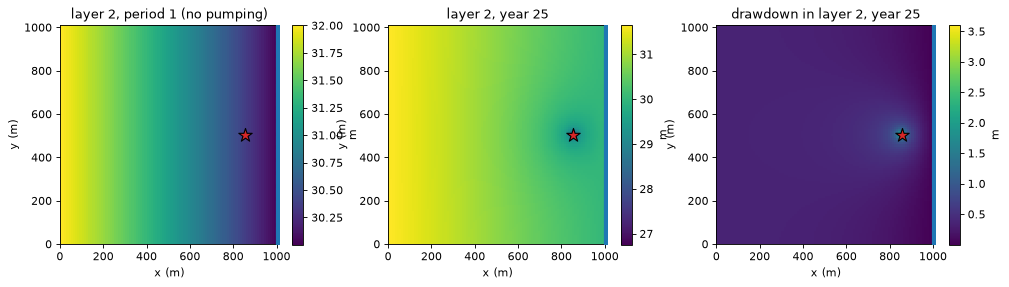

period 1, layer 2, row of the well: head 32.01 m at the west edge, 30.00 m in the stream column, a rise of 2.0 m
head in the well cell at year 25: 26.76 m (layer 2 spans 10 to 20 m), 3.6 m below period 1
the well takes 100.0% of the outflow of its cell at year 25


In [3]:
heads = flopy.utils.HeadFile(str(run.head_file))
h_first = np.asarray(heads.get_data(kstpkper=reader.steps[0]), float).ravel()
h_last = np.asarray(heads.get_data(kstpkper=reader.steps[-1]), float).ravel()
panels = [(h_first, 1, "layer 2, period 1 (no pumping)"), (h_last, 1, f"layer 2, year {N_YEARS}"),
          (h_first - h_last, 1, f"drawdown in layer 2, year {N_YEARS}")]
fig, axes = plt.subplots(1, 3, figsize=(15.0, 4.2))
for ax, (values, layer, title) in zip(axes, panels):
    hbd.plot_cells(run.grb_file, first, values, ax=ax, layer=layer, title=title, overlay=False,
                   label="m", cmap="viridis")
    helpers.mark_well(ax, run.grb_file, first, well_node, layer)
plt.show()

cell = gs.cell_budget(last)
well_row = helpers.SPEC.wells[0][1][0]
h_row = h_first.reshape(3, helpers.SPEC.nrow, helpers.SPEC.ncol)[1, well_row]  # layer 2, row of the well
print(f"period 1, layer 2, row of the well: head {h_row[0]:.2f} m at the west edge, {h_row[-1]:.2f} m in the "
      f"stream column, a rise of {h_row[0] - h_row[-1]:.1f} m")
print(f"head in the well cell at year {N_YEARS}: {h_last[well_node]:.2f} m (layer 2 spans 10 to 20 m), "
      f"{h_first[well_node] - h_last[well_node]:.1f} m below period 1")
print(f"the well takes {700.0 / cell.outflow[well_node]:.1%} of the outflow of its cell at year {N_YEARS}")

Without pumping, lateral inflow and recharge raise the heads by 2.0 m from the stream to the west edge. After 25 years of pumping, the head in the well cell is 3.6 m lower. It stays above the top of layer 2, so the well cell stays fully saturated.

The last line shows that the well is a **strong sink**: all the water flowing into its cell leaves through the well. None flows on. The concentration of the pumped water is then the concentration of the well cell, in a transport model and in `gwsource`. Had the well been a weak sink, both would still give the well the cell's average water, because both assume full mixing.

## 2. Forward tracking: the well's water by source

`gs.track_forward` carries the three tagged sources and the tagged stored water through every step (tutorial 08 explains the scheme). `volume_mode="gwt"` computes the cell water volumes as MF6 GWT does, so that section 3 can compare the two codes step by step.

The share of each source in the pumped water is the tagged volume leaving through the well in a step, divided by the volume pumped in that step. The time axis starts when pumping starts.

forward tracking: 301 steps, 4 groups in 20.2 s


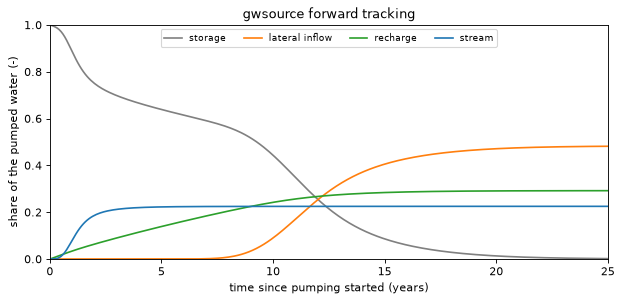

,storage,lateral inflow,recharge,stream
time (yr),,,,
1,0.886,0.000,0.034,0.080
2,0.750,0.000,0.064,0.187
5,0.639,0.000,0.139,0.223
10,0.443,0.090,0.242,0.225
12,0.255,0.253,0.267,0.225
15,0.086,0.405,0.284,0.225
25,0.002,0.482,0.292,0.225


sum of the four shares over all 300 steps with pumping: 1.000000000000 to 1.000000000000
stored water created (+) or lost (-) at step boundaries in gwt volume mode: 98.3 m3 of 3,060,300 m3
water entering from the sources in the 1-day period 1: 761 m3, 0.02% of the water in the aquifer


In [4]:
config = gs.TrackingConfig(porosity=POROSITY, initial_water=INITIAL, volume_mode="gwt")
t0 = time.perf_counter()
fwd = gs.track_forward(reader, SOURCES, config, sinks=DESTINATIONS)
print(f"forward tracking: {len(fwd.steps)} steps, {len(fwd.groups)} groups in {time.perf_counter() - t0:.1f} s")

pumped = helpers.sink_volumes(reader, WELL)  # m3 per step
ours = helpers.well_shares(fwd.outflow_to[WELL], pumped, fwd.totim, start)[GROUPS]
fig, ax = plt.subplots(figsize=(9.0, 3.8))
for group in GROUPS:
    ax.plot(ours.index, ours[group], color=COLOURS[group], label=group)
ax.set_xlim(0.0, N_YEARS)
ax.set_ylim(0.0, 1.0)
ax.set_xlabel("time since pumping started (years)")
ax.set_ylabel("share of the pumped water (-)")
ax.set_title("gwsource forward tracking")
ax.legend(fontsize=8, ncol=4, loc="upper center")
plt.show()
display(helpers.series_at_years(ours, TABLE_YEARS).round(3))

total = ours.sum(axis=1)
print(f"sum of the four shares over all {len(total)} steps with pumping: "
      f"{total.min():.12f} to {total.max():.12f}")
adjustment = float(fwd.balance["storage"]["volume_adjustment"].sum())
print(f"stored water created (+) or lost (-) at step boundaries in gwt volume mode: {adjustment:.1f} m3 "
      f"of {fwd.balance['storage']['storage_start'][0]:,.0f} m3")
entered = float(budget.loc[["INFLOW", "RCH"], ("period 1, steady, no pumping", "in")].sum()) * start
print(f"water entering from the sources in the {start:.0f}-day period 1: {entered:.0f} m3, "
      f"{entered / fwd.balance['storage']['storage_start'][0]:.2%} of the water in the aquifer")

The four shares sum to 1 at every step, to round-off. Each source arrives at its own time:

- The **stream** arrives first. Its share is 1.1 % after 6 months, 18.7 % after 2 years and 22.5 % from year 10 on.
- **Recharge** rises almost linearly for 10 years, to 24.2 %, and reaches 29.2 % at year 25.
- **Lateral inflow** enters at the west edge, 850 m from the well. It first appears after about 7 years, is 9.0 % at year 10 and 48.2 % at year 25.
- The **stored water** falls in two stages. It falls to 63.9 % in the first 5 years, as stream water and recharge arrive. It then falls to 0.2 % at year 25, as lateral inflow arrives.

In gwt volume mode the water volume of a cell is porosity × saturated volume. Here porosity equals the specific yield, so the stored water created at step boundaries (tutorial 08, section 7) comes only from specific storage. It is 98 m³ over 25 years, of 3.06 million m³.

## 3. Comparison with MF6 GWT

Each source now gets its own MF6 GWT model, as the paper ran four MT3D-USGS models (p. 306). `hbd.run_gwt_tracer` builds a GWT model that reads the saved heads and flows (FMI), with upstream advection, no dispersion, porosity 0.1 and `FLOW_IMBALANCE_CORRECTION`. The tagged package gets concentration 1 on every bound (SPC files). All other inflow gets concentration 0. The stored-water model has no tagged package and an initial concentration of 1. The solver tolerance is 10⁻⁹. That is looser than the default of `run_gwt_tracer`, to shorten the runs.

Every cell and every step is compared with the forward tracking above. The arrays of each GWT run are discarded after the comparison to save memory.

four GWT runs in 28.4 s


,"max |c - C|, all cells and steps",mean |c - C|,"max |c - C|, well cell"
storage,4.4e-11,8.7e-13,1.1e-11
lateral inflow,1.0e-10,7.1e-13,2.7e-11
recharge,1.1e-10,5.6e-13,1.0e-11
stream,1.5e-10,1.3e-13,2.5e-11


sum of the four GWT concentrations over all cells and steps: 1.000000000 to 1.000000000


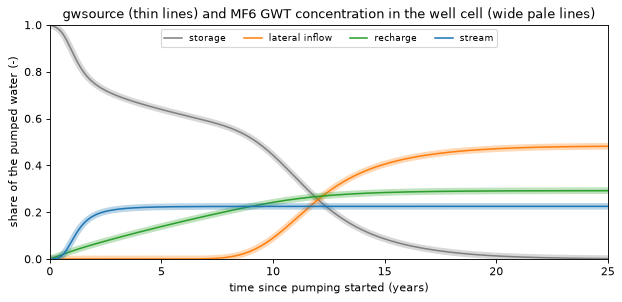

In [5]:
active = first.active
rows, gwt_well = {}, {}
gwt_sum = np.zeros((len(fwd.steps), active.size))
t0 = time.perf_counter()
for group, (tagged, strt) in GWT_RUNS.items():
    ucn = hbd.run_gwt_tracer(run, WORK / f"gwt_{group.replace(' ', '_')}", MF6, POROSITY,
                             tagged=tagged, strt=strt, ims_kwargs=GWT_IMS)
    conc = helpers.gwt_all_cells(ucn, fwd.steps)
    error = np.abs(conc - fwd.source_fraction[group])[:, active]
    rows[group] = {"max |c - C|, all cells and steps": error.max(), "mean |c - C|": error.mean(),
                   "max |c - C|, well cell": error[:, active[:well_node].sum()].max()}
    gwt_well[group] = conc[:, well_node]
    gwt_sum += conc
    del conc, error
print(f"four GWT runs in {time.perf_counter() - t0:.1f} s")
display(pd.DataFrame(rows).T.map(lambda v: f"{v:.1e}"))
print(f"sum of the four GWT concentrations over all cells and steps: "
      f"{gwt_sum[:, active].min():.9f} to {gwt_sum[:, active].max():.9f}")

gwt_series = pd.DataFrame(gwt_well, index=pd.Index((fwd.totim - start) / DAYS, name="time (yr)"))
gwt_series = gwt_series[gwt_series.index > 0.0]
fig, ax = plt.subplots(figsize=(9.0, 3.8))
helpers.plot_well_series(ax, ours, gwt_series, COLOURS)
ax.set_title("gwsource (thin lines) and MF6 GWT concentration in the well cell (wide pale lines)")
ax.legend(fontsize=8, ncol=4, loc="upper center")
plt.show()

The two codes agree to 1.5 × 10⁻¹⁰ or better in every cell at every step. In the well cell they agree to 3 × 10⁻¹¹. These differences are below the GWT solver tolerance of 10⁻⁹. A tighter tolerance makes them smaller, at the cost of longer GWT runs. The four GWT concentrations sum to 1 in every cell, to nine decimals.

So, on this model, a unit-concentration model with upstream weighting and no dispersion gives the concentrations that `gwsource` forward tracking computes. The cost is of the same order. The times printed above are for the four GWT runs and for the one tracking run with all four labels.

## 4. Comparison with the paper's Figure 2

The paper's curves (markers) and the tracked shares (lines):

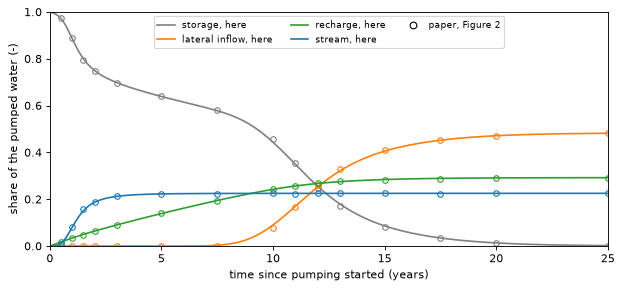

paper (%)                                here (%)                 \
            storage lateral inflow recharge stream  storage lateral inflow   
time (yr)                                                                    
1.0            88.7            0.0      3.3    8.0     88.6            0.0   
2.0            74.7            0.0      6.3   19.0     75.0            0.0   
5.0            63.9            0.0     13.9   22.2     63.9            0.0   
10.0           45.5            7.7     24.3   22.5     44.3            9.0   
12.0           24.8           25.9     26.8   22.5     25.5           25.3   
15.0            8.3           40.9     28.3   22.5      8.6           40.5   
25.0            0.2           48.1     29.2   22.5      0.2           48.2   

                          here - paper (points)                                 
          recharge stream               storage lateral inflow recharge stream  
time (yr)                                                                       
1.0            3.4    8.0                  -0.1            0.0      0.1    0.0  
2.0            6.4   18.7                   0.3            0.0      0.1   -0.3  
5.0           13.9   22.3                  -0.0            0.0     -0.0    0.1  
10.0          24.2   22.5                  -1.2            1.3     -0.1   -0.0  
12.0          26.7   22.5                   0.7           -0.6     -0.1   -0.0  
15.0          28.4   22.5                   0.3           -0.4      0.1   -0.0  
25.0          29.2   22.5                  -0.0            0.1     -0.0   -0.0

largest |here - paper| over the 15 read-off times, in percentage points:
{'storage': '1.2 at year 10.0', 'lateral inflow': '1.3 at year 10.0', 'recharge': '0.1 at year 1.0', 'stream': '0.7 at year 1.5'}


In [6]:
fig, ax = plt.subplots(figsize=(9.0, 3.8))
for group in GROUPS:
    ax.plot(ours.index, ours[group], color=COLOURS[group], label=f"{group}, here")
    ax.plot(PAPER_FIG2.index, PAPER_FIG2[group], "o", color=COLOURS[group], ms=5, mfc="none")
ax.plot([], [], "o", color="k", mfc="none", label="paper, Figure 2")
ax.set_xlim(0.0, N_YEARS)
ax.set_ylim(0.0, 1.0)
ax.set_xlabel("time since pumping started (years)")
ax.set_ylabel("share of the pumped water (-)")
ax.legend(fontsize=8, ncol=3, loc="upper center")
plt.show()

ours_at = helpers.series_at_years(ours, PAPER_YEARS)
difference = 100.0 * (ours_at - PAPER_FIG2)
side_by_side = pd.concat({"paper (%)": 100.0 * PAPER_FIG2, "here (%)": 100.0 * ours_at,
                          "here - paper (points)": difference}, axis=1)
display(side_by_side.loc[list(TABLE_YEARS)].round(1))
largest = difference.abs()
print("largest |here - paper| over the 15 read-off times, in percentage points:")
print({g: f"{largest[g].max():.1f} at year {largest[g].idxmax()}" for g in GROUPS})

The rebuilt model reproduces the published curves. At year 25 the shares are 48.2 % lateral inflow, 29.2 % recharge and 22.5 % stream, against 48 %, 29 % and 23 % in the paper's text (p. 306). Over the 15 read-off times, the largest differences are 1.3 percentage points for lateral inflow and 1.2 points for stored water. Both are at year 10, on the lateral-inflow front. Recharge and stream differ by 0.7 points or less, within the accuracy of the read-off.

The paper's description of its Figure 2 (p. 306) also holds here:

- at first, all the pumped water is stored water;
- the recharge share rises approximately linearly over 10 to 15 years, then stabilises;
- the stream share rises within the first year and stabilises within 5 years;
- lateral inflow reaches the well between 10 and 15 years;
- the stored-water share falls in two stages, first as stream water replaces the water east of the well, then as lateral inflow replaces the water west of it.

The largest differences are where a front arrives: the stream in the first two years, and lateral inflow between years 8 and 15. There the transport scheme and the time step matter most (section 6).

## 5. The long-time limit

After 25 years the storage terms are close to 0, so the flows are steady. The tracked shares then tend to those of a steady **backward trace** (tutorial 01) of the last step's flows: the fraction of the well's water that entered through each source, under full mixing, with no time limit. The rows also include the same model with K read as ft/d (`FT`), run with 25 yearly steps, to check the conductivity assumption of section 1.

In [7]:
run_ft = helpers.build_bedekar(WORK / "model_ft", MF6, spec=replace(helpers.SPEC, k=10.0 * FT),
                               kv=1.0 * FT, n_years=N_YEARS, nstp=N_YEARS)
reader_ft = gs.open_model(run_ft.ws, boundnames=True)
limit = pd.DataFrame({
    "steady trace, year-25 flows": helpers.steady_shares(last, WELL, PACKAGE_GROUPS),
    "steady trace, K in ft/d": helpers.steady_shares(reader_ft.read(reader_ft.steps[-1]), WELL,
                                                     PACKAGE_GROUPS),
    "tracked, year 25": ours.iloc[-1],
    "paper, year 25": PAPER_FIG2.iloc[-1],
}).reindex(GROUPS).fillna(0.0)
display(limit.round(3))
h_ft = flopy.utils.HeadFile(str(run_ft.head_file)).get_data(kstpkper=reader_ft.steps[-1]).ravel()
print(f"head in the well cell at year {N_YEARS}: {h_last[well_node]:.2f} m with K in m/d, "
      f"{h_ft[well_node]:.2f} m with K in ft/d")

,"steady trace, year-25 flows","steady trace, K in ft/d","tracked, year 25","paper, year 25"
storage,0.000,0.000,0.002,0.002
lateral inflow,0.483,0.482,0.482,0.481
recharge,0.292,0.291,0.292,0.292
stream,0.225,0.226,0.225,0.225


head in the well cell at year 25: 26.76 m with K in m/d, 19.07 m with K in ft/d


The tracked shares at year 25 match the steady trace to within 0.2 percentage points. The 0.2 % of stored water still being pumped makes up the difference. The paper's year-25 values are the same long-time limit.

Reading K as ft/d instead of m/d lowers the head in the well cell from 26.8 m to 19.1 m. It moves the steady shares by 0.1 percentage points. The shares are set by the specified inflow, recharge and pumping rates, not by K. The assumption on the units therefore does not affect the comparison.

## 6. Time-step size and numerical dispersion

The paper did not simulate dispersion. It notes that numerical dispersion changes the timing of source arrival (p. 307). With full mixing and implicit time stepping there are two sources of it:

- **in space:** each 10 m × 10 m × 10 m cell is fully mixed, so a sharp front is smeared over several cells ([tutorial 11](../11_numerical_dispersion/11_numerical_dispersion.ipynb));
- **in time:** in one implicit step, tagged water can cross several cells. A measure is the cell Courant number $O_i\,\Delta t / V_i$: the volume flowing out of a cell in one step, over the water volume of the cell. Above 1, water passes through the cell more than once per step.

`TrackingConfig.substeps` splits every flow step into equal transport sub-steps without changing the flow model (tutorial 08, section 9). The cell below computes the Courant numbers of the 30-day steps, then reruns the first 15 years with 4 sub-steps, that is 7.6-day transport steps. `helpers.window` passes only the first 15 years of steps to the tracking.

Courant number of the 30.4-day steps at year 25: largest 213 (well cell), 2459 of 30603 cells above 1, all within 220 m of the well


4 sub-steps per flow step, 15 years: 14.7 s


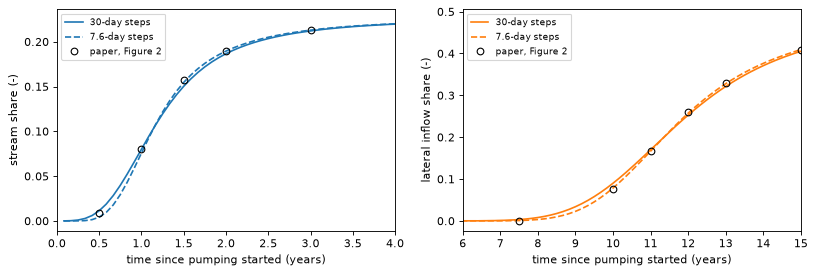

,"stream, 30-day","stream, 7.6-day","stream, paper","lateral, 30-day","lateral, 7.6-day","lateral, paper"
time (yr),,,,,,
0.5,1.1,0.4,0.9,0.0,0.0,0.0
1.0,8.0,7.6,8.0,0.0,0.0,0.0
1.5,15.0,15.5,15.7,0.0,0.0,0.0
2.0,18.7,19.0,19.0,0.0,0.0,0.0
3.0,21.2,21.3,21.3,0.0,0.0,0.0
5.0,22.3,22.3,22.2,0.0,0.0,0.0
7.5,22.4,22.4,22.4,0.3,0.1,0.0
10.0,22.5,22.5,22.5,9.0,7.9,7.7
11.0,22.5,22.5,22.4,17.0,16.7,16.6


30.4-day steps: largest |here - paper| up to year 15: 1.3 percentage points
7.6-day steps: largest |here - paper| up to year 15: 0.6 percentage points


In [8]:
delt = reader.step_length(reader.steps[-1])
water = POROSITY * last.area * last.saturated_thickness  # m3 of water per cell
courant = gs.cell_budget(last).outflow * delt / water
distance = np.hypot(*(gs.export.cell_centres(run.grb_file) - gs.export.cell_centres(run.grb_file)[well_node]).T)
fast = courant > 1.0
print(f"Courant number of the {delt:.1f}-day steps at year {N_YEARS}: largest {courant.max():.0f} (well cell), "
      f"{fast.sum()} of {active.sum()} cells above 1, all within {distance[fast].max():.0f} m of the well")

win = helpers.window(reader, start + SUBSTEP_YEARS * DAYS)
config_sub = gs.TrackingConfig(porosity=POROSITY, initial_water=INITIAL, volume_mode="gwt",
                               substeps=SUBSTEPS, keep_series=False)
t0 = time.perf_counter()
fwd_sub = gs.track_forward(win, SOURCES, config_sub, sinks=DESTINATIONS)
print(f"{SUBSTEPS} sub-steps per flow step, {SUBSTEP_YEARS} years: {time.perf_counter() - t0:.1f} s")
fine = helpers.well_shares(fwd_sub.outflow_to[WELL], pumped[:len(win.steps)], fwd_sub.totim, start)[GROUPS]

fig, axes = plt.subplots(1, 2, figsize=(12.0, 3.6))
for ax, group, (x0, x1) in zip(axes, ("stream", "lateral inflow"), ((0.0, 4.0), (6.0, SUBSTEP_YEARS))):
    ax.plot(ours.index, ours[group], color=COLOURS[group], label="30-day steps")
    ax.plot(fine.index, fine[group], color=COLOURS[group], ls="--", label=f"{delt / SUBSTEPS:.1f}-day steps")
    ax.plot(PAPER_FIG2.index, PAPER_FIG2[group], "o", color="k", mfc="none", label="paper, Figure 2")
    ax.set_xlim(x0, x1)
    ax.set_xlabel("time since pumping started (years)")
    ax.set_ylabel(f"{group} share (-)")
    ax.legend(fontsize=8)
plt.show()

years = [y for y in PAPER_YEARS if y <= SUBSTEP_YEARS]
compare = pd.DataFrame({
    "stream, 30-day": helpers.series_at_years(ours, years)["stream"],
    f"stream, {delt / SUBSTEPS:.1f}-day": helpers.series_at_years(fine, years)["stream"],
    "stream, paper": PAPER_FIG2.loc[years, "stream"],
    "lateral, 30-day": helpers.series_at_years(ours, years)["lateral inflow"],
    f"lateral, {delt / SUBSTEPS:.1f}-day": helpers.series_at_years(fine, years)["lateral inflow"],
    "lateral, paper": PAPER_FIG2.loc[years, "lateral inflow"],
})
display((100.0 * compare).round(1))
paper_years = PAPER_FIG2.loc[years]
for name, shares in ((f"{delt:.1f}-day", ours), (f"{delt / SUBSTEPS:.1f}-day", fine)):
    gap = 100.0 * (helpers.series_at_years(shares, years) - paper_years).abs().to_numpy().max()
    print(f"{name} steps: largest |here - paper| up to year {SUBSTEP_YEARS}: {gap:.1f} percentage points")

With 30-day steps the Courant number is 213 in the well cell and above 1 in 2459 cells around the well.

Shorter transport steps make both fronts steeper. Less of each source arrives early. The curves catch up later. On the lateral-inflow front at year 10, the share falls from 9.0 % to 7.9 %. The paper shows 7.7 %. On the stream front at 6 months it falls from 1.1 % to 0.4 %. The paper shows 0.9 %. The late values do not change, because the time step changes the spread of the arrivals, not the long-time limit.

With 7.6-day steps the largest difference from the paper over the first 15 years falls from 1.3 to 0.6 percentage points. That is within the accuracy of the read-off. The remaining differences can come from the read-off, from the transport step or from the advection scheme of the MT3D-USGS runs, which the paper does not report.

## 7. Backward tracking in time: the time-limited contributing area

The unit-concentration method answers "how much of the pumped water came from each source?" To find **where** in the aquifer the pumped water was at the start, it would need one transport run per zone of the aquifer. Backward tracking (`gs.track_backward`, tutorial 08 section 5) gives this in one run: for the water in every cell at the start of the simulation, the fraction that leaves through the well within the simulated time.

The cell below runs the adjoint four times, with the simulation cut at 1, 5, 10 and 25 years of pumping (`helpers.window`). Each run gives a time-limited contributing area. The adjoint fractions $w$ are mapped for layer 2, the layer of the well.

backward tracking, 4 time limits: 21.2 s


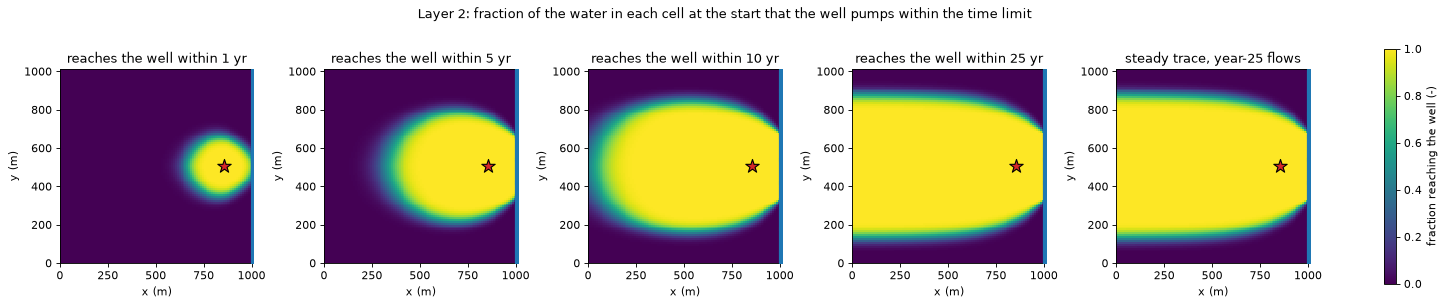

,stored water pumped (m3),all water pumped (m3),stored water share,"area with w > 0.5, layer 2 (ha)","cells with w > 0.5, layer 1","cells with w > 0.5, layer 2","cells with w > 0.5, layer 3"
1 yr,244412.0,255675.0,0.956,8.4,766.0,841.0,756.0
5 yr,972984.0,1278375.0,0.761,32.2,3192.0,3220.0,3172.0
10 yr,1694676.0,2556750.0,0.663,56.9,5665.0,5691.0,5661.0
25 yr,2045391.0,6391875.0,0.320,68.2,6813.0,6825.0,6829.0


steady trace, cells with F > 0.5 in layers 1 to 3: [6817, 6829, 6831]


In [9]:
bwd = {}
t0 = time.perf_counter()
for years in WINDOWS:
    config_w = replace(config, keep_series=(years == N_YEARS))  # every step only for the 25-year run
    bwd[years] = gs.track_backward(helpers.window(reader, start + years * DAYS), DESTINATIONS,
                                   config_w, sources=SOURCES)
print(f"backward tracking, {len(WINDOWS)} time limits: {time.perf_counter() - t0:.1f} s")

steady = gs.backward(last, {WELL: gs.select(last, boundnames=[WELL])})
panels = [(bwd[years].fraction_through[WELL][0], 1, f"reaches the well within {years} yr")
          for years in WINDOWS]
panels.append((steady.fraction_through[WELL], 1, "steady trace, year-25 flows"))
fig, axes = helpers.map_panels(run.grb_file, first, panels, well_node, cmap="viridis", vmin=0.0, vmax=1.0,
                               label="fraction reaching the well (-)")
fig.suptitle("Layer 2: fraction of the water in each cell at the start that the well pumps within the time limit")
plt.show()

rows = {}
for years in WINDOWS:
    w0 = bwd[years].fraction_through[WELL][0]
    rows[f"{years} yr"] = {
        "stored water pumped (m3)": float(bwd[years].initial_volume_from[WELL].sum()),
        "all water pumped (m3)": float(bwd[years].destination_outflow[WELL].sum()),
        "stored water share": float(bwd[years].initial_volume_from[WELL].sum()
                                    / bwd[years].destination_outflow[WELL].sum()),
        "area with w > 0.5, layer 2 (ha)": float(first.area.reshape(3, -1)[1][w0.reshape(3, -1)[1] > 0.5].sum()) / 1.0e4,
        **{f"cells with w > 0.5, layer {k + 1}": int((w0.reshape(3, -1)[k] > 0.5).sum()) for k in range(3)},
    }
display(pd.DataFrame(rows).T.round({"stored water pumped (m3)": 0, "all water pumped (m3)": 0,
                                    "stored water share": 3, "area with w > 0.5, layer 2 (ha)": 1}))
f_steady = steady.fraction_through[WELL].reshape(3, -1)
print("steady trace, cells with F > 0.5 in layers 1 to 3:", [int((f_steady[k] > 0.5).sum()) for k in range(3)])

Each map shows, for the water in each cell of layer 2 at the start of the simulation, the fraction that the well pumps within the time limit. The table counts the cells where this fraction is above 0.5, and the volumes behind the shares of sections 2 and 4.

- Within 1 year, the well pumps the water of about 840 cells (8.4 ha) per layer around it, from the well to the stream. This water makes up 96 % of all the water pumped in that year.
- The area grows up-gradient, to the west, because the water between the well and the stream is replaced by stream water. It covers about 3200 cells per layer within 5 years and 5700 within 10 years.
- Within 25 years it covers about 6800 cells per layer. That is nearly the steady contributing area of the year-25 flows (right, no time limit), which reaches the west edge.
- The fractions are almost the same in the three layers. The layers are 10 m thick and the vertical conductivity is 1 m/d, so water crosses between them within each cell.

The forward run gave the same information as a share of the pumped water: 32 % of the water pumped over 25 years was stored water. The backward run adds where that water was. The next cell checks that the two runs agree. The adjoint splits the well's 25-year outflow by source. The parts must add up to the pumped volume (closure). Forward and backward runs must give the same volume from each source to the well (duality, tutorial 08 section 6):

In [10]:
b25 = bwd[N_YEARS]
closure = gs.tracking.backward_closure(b25, WELL)
rows = {}
for group in GROUPS:
    check = gs.tracking_duality(fwd, group, b25, WELL)
    rows[group] = {"forward (m3)": check.rhs, "backward (m3)": check.lhs,
                   "share of the 25-year pumping": check.lhs / closure.rhs,
                   "relative difference": check.relative_error}
display(pd.DataFrame(rows).T.round({"forward (m3)": 0, "backward (m3)": 0, "share of the 25-year pumping": 3}))
print(f"closure: sources + stored water = {closure.lhs:,.0f} m3, well outflow = {closure.rhs:,.0f} m3 "
      f"(relative error {closure.relative_error:.1e})")

,forward (m3),backward (m3),share of the 25-year pumping,relative difference
storage,2045391.0,2045391.0,0.320,1.138318e-16
lateral inflow,1558576.0,1558576.0,0.244,1.493867e-16
recharge,1430136.0,1430136.0,0.224,8.140159e-16
stream,1357772.0,1357772.0,0.212,1.714800e-16


closure: sources + stored water = 6,391,875 m3, well outflow = 6,391,875 m3 (relative error 5.8e-16)


Over the 25 years the well pumped 6.39 million m³: 32.0 % stored water, 24.4 % lateral inflow, 22.4 % recharge and 21.2 % stream water. These are cumulative shares, so they differ from the year-25 shares of section 2. Forward and backward give the same volumes to about 10⁻¹⁶. The parts add up to the pumped volume. Both checks are identities of the discrete scheme. They show that the code's bookkeeping adds up, not that the model is right.

The backward run also shows where the water that entered during the 25 years crossed the model boundary. For recharge, the adjoint fraction of each step is the fraction of the recharge falling on a cell in that step that the well pumps by year 25. Its time average is mapped on the left. For the stream, the right panel gives the stream water entering each row of the stream column (three layers) that the well pumps by year 25. It is the water entering those cells minus their recharge, computed in the same way.

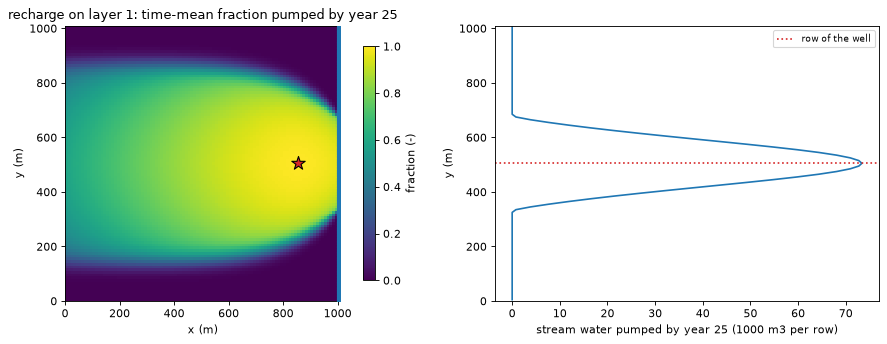

time-mean recharge fraction on the row of the well: 0.60 next to the west edge, 1.00 at most
recharge pumped: map 1,430,136 m3, budget 1,430,136 m3
stream water pumped: profile 1,357,772 m3, budget 1,357,772 m3; 35 of 101 rows above 1 % of the largest
those rows lie within 170 m of the well's row


In [11]:
w_time = (b25.delt[:, None] * b25.fraction_through[WELL]).sum(axis=0)  # integral of w over time [d]
rch = gs.select(last, package="RCH")
rch_rate = np.bincount(last.term_cell[rch.terms], last.term_flow[rch.terms], minlength=active.size)
recharge_fraction = np.where(rch_rate > 0.0, w_time / b25.delt.sum(), np.nan)
stream_cells = hbd.feature_cells(last, "RIV")
entered = b25.volume_from[WELL].sum(axis=0)  # m3 per cell entering through its source terms
stream_water = entered[stream_cells] - rch_rate[stream_cells] * w_time[stream_cells]
rows_of = (stream_cells % (helpers.SPEC.nrow * helpers.SPEC.ncol)) // helpers.SPEC.ncol
per_row = np.bincount(rows_of, stream_water, minlength=helpers.SPEC.nrow)

fig, (ax_map, ax_row) = plt.subplots(1, 2, figsize=(12.0, 4.4), gridspec_kw={"width_ratios": [1.2, 1.0]})
hbd.plot_cells(run.grb_file, first, recharge_fraction, ax=ax_map, layer=0, overlay=False, cmap="viridis",
               vmin=0.0, vmax=1.0, title="recharge on layer 1: time-mean fraction pumped by year 25",
               label="fraction (-)")
helpers.mark_well(ax_map, run.grb_file, first, well_node, 0)
y = helpers.SPEC.ly - (np.arange(helpers.SPEC.nrow) + 0.5) * helpers.SPEC.delc
ax_row.plot(per_row / 1000.0, y, color=COLOURS["stream"])
ax_row.axhline(helpers.SPEC.xy(helpers.SPEC.wells[0][1])[1], color="tab:red", ls=":", label="row of the well")
ax_row.set_xlabel("stream water pumped by year 25 (1000 m3 per row)")
ax_row.set_ylabel("y (m)")
ax_row.set_ylim(0.0, helpers.SPEC.ly)
ax_row.legend(fontsize=8)
fig.tight_layout()
plt.show()

recharge_total = float(b25.volume_from_by_package[WELL]["RCH"].sum())
stream_total = float(b25.volume_from_by_package[WELL]["RIV"].sum())
row = recharge_fraction.reshape(3, helpers.SPEC.nrow, helpers.SPEC.ncol)[0, helpers.SPEC.wells[0][1][0]]
print(f"time-mean recharge fraction on the row of the well: {row[1]:.2f} next to the west edge, "
      f"{np.nanmax(row):.2f} at most")
print(f"recharge pumped: map {float(np.nansum(recharge_fraction * rch_rate)) * b25.delt.sum():,.0f} m3, "
      f"budget {recharge_total:,.0f} m3")
print(f"stream water pumped: profile {per_row.sum():,.0f} m3, budget {stream_total:,.0f} m3; "
      f"{(per_row > 0.01 * per_row.max()).sum()} of {helpers.SPEC.nrow} rows above 1 % of the largest")
feeding_rows = np.flatnonzero(per_row > 0.01 * per_row.max())
print(f"those rows lie within {np.abs(feeding_rows - helpers.SPEC.wells[0][1][0]).max() * helpers.SPEC.delc:.0f} m "
      f"of the well's row")

The time-mean fraction is 1.00 near the well. On the row of the well it falls to 0.60 next to the west edge. It falls to 0 at the north and south edges of the contributing area. Recharge that falls far from the well needs most of the 25 years to arrive, so the recharge of the early years reaches the well and that of the late years does not. The stream water comes from 35 of the 101 stream rows, within about 170 m of the well's row. The map and the profile add up to the recharge and stream volumes of the closure table.

A unit-concentration model gives the same maps only with one transport run per recharge cell or stream reach. The backward run gives them for every cell at once.

## What the example does not reproduce

- **The real-world application.** The paper's second example, recharge at the City of Phoenix ASR wells (its Figure 3), uses a regional MODFLOW-NWT / MT3D-USGS model that is not published. It is not rebuilt here.
- **The exact transport set-up.** The paper does not give the MT3D-USGS advection scheme, the transport step or the solver settings. The fronts differ by up to 1.3 percentage points with 30-day steps and 0.6 points with 7.6-day steps (sections 4 and 6). A difference this small cannot be attributed more precisely.
- **The storage tag in period 1.** The paper fixes the concentration at 1 in every cell during period 1. Here the water present at the start of the 1-day period 1 is tagged instead. The difference is the 760 m³ that enters in that day, 0.02 % of the water in the aquifer.
- **Mechanical dispersion.** The paper mentions that dispersion can be added to the unit-concentration method if appropriate (p. 306). `gwsource` tracking has no dispersion. For a dispersive unit-concentration run, use MF6 GWT with a DSP package.

## Key points

- A unit-concentration model with upstream weighting and no dispersion solves the same equation as `gwsource` forward tracking. On this model the two agree to 1.5 × 10⁻¹⁰ in every cell at every step. The four shares sum to 1.
- The rebuilt model reproduces the paper's Figure 2 to within 1.3 percentage points with 30-day steps, and 0.6 points with 7.6-day transport steps. At year 25: 48.2 % lateral inflow, 29.2 % recharge, 22.5 % stream, against 48 %, 29 % and 23 % in the paper.
- The share of stored water needs only a tag on the water present at the start (`initial_water`), as the paper's C = 1 in every cell.
- The late shares equal those of a steady backward trace of the final flows. The early shares, and the timing of each front, depend on the transport time step. Shorter steps make the fronts steeper.
- Backward tracking adds what the unit-concentration method does not give in one run: the time-limited contributing area of the well, and where the pumped recharge and stream water entered. Forward and backward results agree to round-off (duality, closure), as identities of the scheme require.

## Next

Go back to the [tutorial index](../README.md), or go on to [11 · Numerical dispersion](../11_numerical_dispersion/11_numerical_dispersion.ipynb), which measures how wide full mixing makes the edge of a capture zone.